In [262]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal


# Sorry for the typos in advance

print("Installations Working!")

Installations Working!


# Load Data Sets

In [263]:
# Load Datasets
import pandas as pd

df_white = pd.read_csv("wine+quality/winequality-white.csv", sep=";")
df_red = pd.read_csv("wine+quality/winequality-red.csv", sep=";")

df = df_white #pd.concat([df_red, df_white], ignore_index = True)
wine_X = df.drop(columns="quality").to_numpy()   # features, shape (4898, 11)
wine_y = df["quality"].to_numpy()                # labels,   shape (4898,)

#print(df.head())
print(wine_X.shape, wine_y.shape)
print(df["quality"].value_counts().sort_index())   # samples per quality score

(4898, 11) (4898,)
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


In [264]:

base = "UCI HAR Dataset/"

X_train = pd.read_csv(base + "train/X_train.txt", sep=r"\s+", header=None).to_numpy()
y_train = pd.read_csv(base + "train/y_train.txt", sep=r"\s+", header=None).to_numpy().ravel()
X_test  = pd.read_csv(base + "test/X_test.txt",  sep=r"\s+", header=None).to_numpy()
y_test  = pd.read_csv(base + "test/y_test.txt",  sep=r"\s+", header=None).to_numpy().ravel()

# combine train and test into one dataset
HAR_X = np.vstack([X_train, X_test])          # (10299, 561)
HAR_y = np.concatenate([y_train, y_test])     # (10299,)

print(HAR_X.shape, HAR_y.shape)
print(np.unique(HAR_y, return_counts=True))   # samples per activity

(10299, 561) (10299,)
(array([1, 2, 3, 4, 5, 6]), array([1722, 1544, 1406, 1777, 1906, 1944]))


# Wine Quality Dataset

### 

In [265]:
X, y = wine_X, wine_y 

X = (wine_X - wine_X.mean(axis=0)) / wine_X.std(axis=0)
d = X.shape[1]   
alpha = .01

classes = np.unique(y)

print(f"Unique Counts per Label: {np.unique(y, return_counts=True)}")
print(f"Unique Clases: {len(classes)} | Class Labels: {classes}")

# Mean Estimations

est_mus, est_covs, est_priors = [], [], []

for c in classes:
    mu_k = np.mean(X[y == c], axis=0)
    est_mus.append(mu_k)

    prior_k = np.mean(y == c)
    est_priors.append(prior_k)

    # Cov Reg
    cov_k = np.cov(X[y == c], rowvar=False)
    rank_k = np.linalg.matrix_rank(cov_k)

    lamda = alpha * np.trace(cov_k) / rank_k

    cov_reg = cov_k + lamda * np.eye(d)


    est_covs.append(cov_reg)

    # Checking the covs are valid
    print(f"Matrix Rank for Class {c}: {np.linalg.matrix_rank(cov_reg)}")


Unique Counts per Label: (array([3, 4, 5, 6, 7, 8, 9]), array([  20,  163, 1457, 2198,  880,  175,    5]))
Unique Clases: 7 | Class Labels: [3 4 5 6 7 8 9]
Matrix Rank for Class 3: 11
Matrix Rank for Class 4: 11
Matrix Rank for Class 5: 11
Matrix Rank for Class 6: 11
Matrix Rank for Class 7: 11
Matrix Rank for Class 8: 11
Matrix Rank for Class 9: 11


### MAP Classification

In [266]:
# ERM Classifier

scores = np.column_stack([
    multivariate_normal(est_mus[k], est_covs[k]).logpdf(X) + np.log(est_priors[k])
    for k in range(len(classes))
])
print(f"Shape: {scores.shape}")

D = classes[np.argmax(scores, axis=1)]
print(f"Accuracy: {np.mean(D == y):.4f}")

Shape: (4898, 7)
Accuracy: 0.4955


In [267]:
# P(D=j | L=j) for each class: fraction of class j classified correctly
correct_rates = np.array([np.mean(D[y == c] == c) for c in classes])

priors = np.array(est_priors)          # same order as classes

P_error = 1 - np.sum(correct_rates * priors)

print(f"P(error) = {P_error:.4f}")
print(f"Error Count: {np.sum(D != y)}")
print(f"Check (1 - accuracy) = {1 - np.mean(D == y):.4f}")   # should match

P(error) = 0.5045
Error Count: 2471
Check (1 - accuracy) = 0.5045


### ML Classification

In [268]:
scores_ML = np.column_stack([
    multivariate_normal(est_mus[k], est_covs[k]).logpdf(X)
    for k in range(len(classes))
])
D_ML = classes[np.argmax(scores_ML, axis=1)]

print(f"Accuracy: {np.mean(D_ML == y):.4f}")

# P(D=j | L=j) for each class: fraction of class j classified correctly
correct_rates = np.array([np.mean(D_ML[y == c] == c) for c in classes])

priors = np.array(est_priors)          # same order as classes

P_error = 1 - np.sum(correct_rates * priors)

print(f"P(error) = {P_error:.4f}")
print(f"Check (1 - accuracy) = {1 - np.mean(D_ML == y):.4f}")   # should match

Accuracy: 0.3771
P(error) = 0.6229
Check (1 - accuracy) = 0.6229


### Visualization


In [269]:
K = len(classes)
counts = np.zeros((K, K), dtype=int)

for i, ci in enumerate(classes):        # decision
    for j, cj in enumerate(classes):    # true label
        counts[i, j] = np.sum((D == ci) & (y == cj))

print(pd.DataFrame(counts, index=classes, columns=classes))

   3   4    5    6    7    8  9
3  8   3   10    2    0    0  0
4  2  39   48   28    2    0  0
5  3  70  804  461   27    3  0
6  4  39  436  909  192   47  0
7  2  11  158  782  647  110  0
8  1   1    1   16   12   15  0
9  0   0    0    0    0    0  5


### PCA Transformation

In [270]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
Z = pca.fit_transform(X)          # shape (N, 3)

print(Z.shape)
print("Variance explained:", np.round(pca.explained_variance_ratio_, 3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

(4898, 3)
Variance explained: [0.293 0.143 0.111]
Total: 0.547


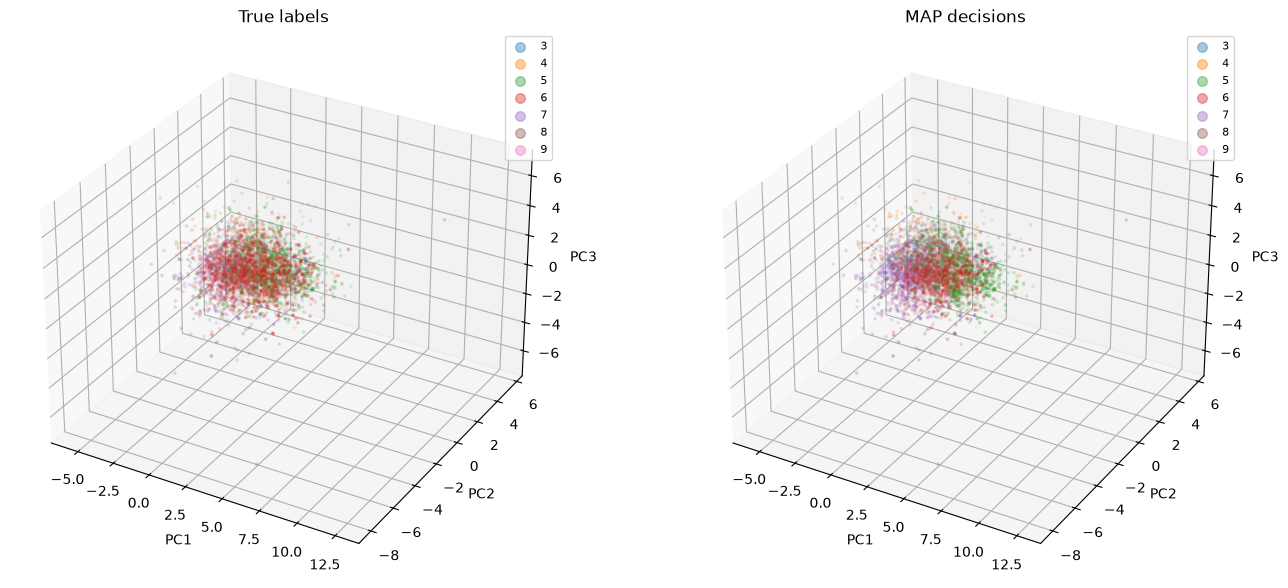

In [271]:
fig = plt.figure(figsize=(14, 6))
for p, (labels, name) in enumerate([(y, "True labels"), (D, "MAP decisions")], start=1):
    ax = fig.add_subplot(1, 2, p, projection="3d")
    for c in classes:
        pts = Z[labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=3, alpha=0.4, label=str(c))
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title(name)
    ax.legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()

# UCI HAR Dataset

### 

In [272]:
X, y = HAR_X, HAR_y 
d = X.shape[1]   

classes = np.unique(y)

print(f"Unique Counts per Label: {np.unique(y, return_counts=True)}")

# Mean Estimations

est_mus, est_covs, est_priors = [], [], []

for c in classes:
    mu_k = np.mean(X[y == c], axis=0)
    est_mus.append(mu_k)

    prior_k = np.mean(y == c)
    est_priors.append(prior_k)

    # Cov Reg
    cov_k = np.cov(X[y == c], rowvar=False)
    rank_k = np.linalg.matrix_rank(cov_k)



    lamda = np.trace(cov_k) / np.linalg.matrix_rank(cov_k)

    cov_reg = cov_k + lamda * np.eye(d)


    est_covs.append(cov_reg)

    # Checking the covs are valid
    print(f"Matrix Rank for Class {c}: {np.linalg.matrix_rank(cov_reg)}")


Unique Counts per Label: (array([1, 2, 3, 4, 5, 6]), array([1722, 1544, 1406, 1777, 1906, 1944]))
Matrix Rank for Class 1: 561
Matrix Rank for Class 2: 561
Matrix Rank for Class 3: 561
Matrix Rank for Class 4: 561
Matrix Rank for Class 5: 561
Matrix Rank for Class 6: 561


### Map Classification


In [273]:
# ERM Classifier

scores = np.column_stack([
    multivariate_normal(est_mus[k], est_covs[k]).logpdf(X) + np.log(est_priors[k])
    for k in range(len(classes))
])
print(f"Shape: {scores.shape}")

D = classes[np.argmax(scores, axis=1)]
print(f"Accuracy: {np.mean(D == y):.4f}")
'''

def g(mu, C):
    return multivariate_normal(mu, C).pdf(X)


mu_1, mu_2, mu_3, mu_4, mu_5, mu_6 = est_mus[0], est_mus[1], est_mus[2], est_mus[3], est_mus[4], est_mus[5]
cov_1, cov_2, cov_3, cov_4, cov_5, cov_6 = est_covs[0], est_covs[1], est_covs[2], est_covs[3], est_covs[4], est_covs[5]
p_1, p_2, p_3, p_4, p_5, p_6 =  est_priors[0], est_priors[1], est_priors[2], est_priors[3], est_priors[4], est_priors[5]

scores = np.stack([
    g(mu_1, cov_1) * p_1,
    g(mu_2, cov_2) * p_2,
    g(mu_3, cov_3) * p_3,
    g(mu_4, cov_4) * p_4,
    g(mu_5, cov_5) * p_5,
    g(mu_6, cov_6) * p_6, 
    ], axis=1)

D = np.argmax(scores, axis=1) + 1     # decisions, 1/2/3


scores.shape

print(f"Accuracy: {np.mean(D == y)}")

'''

Shape: (10299, 6)
Accuracy: 0.7048


'\n\ndef g(mu, C):\n    return multivariate_normal(mu, C).pdf(X)\n\n\nmu_1, mu_2, mu_3, mu_4, mu_5, mu_6 = est_mus[0], est_mus[1], est_mus[2], est_mus[3], est_mus[4], est_mus[5]\ncov_1, cov_2, cov_3, cov_4, cov_5, cov_6 = est_covs[0], est_covs[1], est_covs[2], est_covs[3], est_covs[4], est_covs[5]\np_1, p_2, p_3, p_4, p_5, p_6 =  est_priors[0], est_priors[1], est_priors[2], est_priors[3], est_priors[4], est_priors[5]\n\nscores = np.stack([\n    g(mu_1, cov_1) * p_1,\n    g(mu_2, cov_2) * p_2,\n    g(mu_3, cov_3) * p_3,\n    g(mu_4, cov_4) * p_4,\n    g(mu_5, cov_5) * p_5,\n    g(mu_6, cov_6) * p_6, \n    ], axis=1)\n\nD = np.argmax(scores, axis=1) + 1     # decisions, 1/2/3\n\n\nscores.shape\n\nprint(f"Accuracy: {np.mean(D == y)}")\n\n'

In [274]:
# P(D=j | L=j) for each class: fraction of class j classified correctly
correct_rates = np.array([np.mean(D[y == c] == c) for c in classes])

priors = np.array(est_priors)          # same order as classes

P_error = 1 - np.sum(correct_rates * priors)

print(f"P(error) = {P_error:.4f}")
print(f"Check (1 - accuracy) = {1 - np.mean(D == y):.4f}")   # should match

P(error) = 0.2952
Check (1 - accuracy) = 0.2952


### ML Classification


In [279]:
scores_ML = np.column_stack([
    multivariate_normal(est_mus[k], est_covs[k]).logpdf(X)
    for k in range(len(classes))
])
D_ML = classes[np.argmax(scores_ML, axis=1)]

print(f"Accuracy: {np.mean(D_ML == y):.4f}")

# P(D=j | L=j) for each class: fraction of class j classified correctly
correct_rates = np.array([np.mean(D_ML[y == c] == c) for c in classes])

priors = np.array(est_priors)          # same order as classes

P_error = 1 - np.sum(correct_rates * priors)

print(f"P(error) = {P_error:.4f}")
print(f"Error Count: {np.sum(D != y)}")

print(f"Check (1 - accuracy) = {1 - np.mean(D_ML == y):.4f}")   # should match

Accuracy: 0.7047
P(error) = 0.2953
Error Count: 3040
Check (1 - accuracy) = 0.2953


### Visualization

In [276]:
K = len(classes)
counts = np.zeros((K, K), dtype=int)

for i, ci in enumerate(classes):        # decision
    for j, cj in enumerate(classes):    # true label
        counts[i, j] = np.sum((D == ci) & (y == cj))

print(pd.DataFrame(counts, index=classes, columns=classes))

      1     2    3     4     5     6
1  1722     1  512     0     0     0
2     0  1538  794     0     0     0
3     0     0  100     0     0     0
4     0     0    0   494     1   444
5     0     5    0  1283  1905     0
6     0     0    0     0     0  1500


### PCA Transformation

In [277]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
Z = pca.fit_transform(X)          # shape (N, 3)

print(Z.shape)
print("Variance explained:", np.round(pca.explained_variance_ratio_, 3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

(10299, 3)
Variance explained: [0.622 0.048 0.04 ]
Total: 0.71


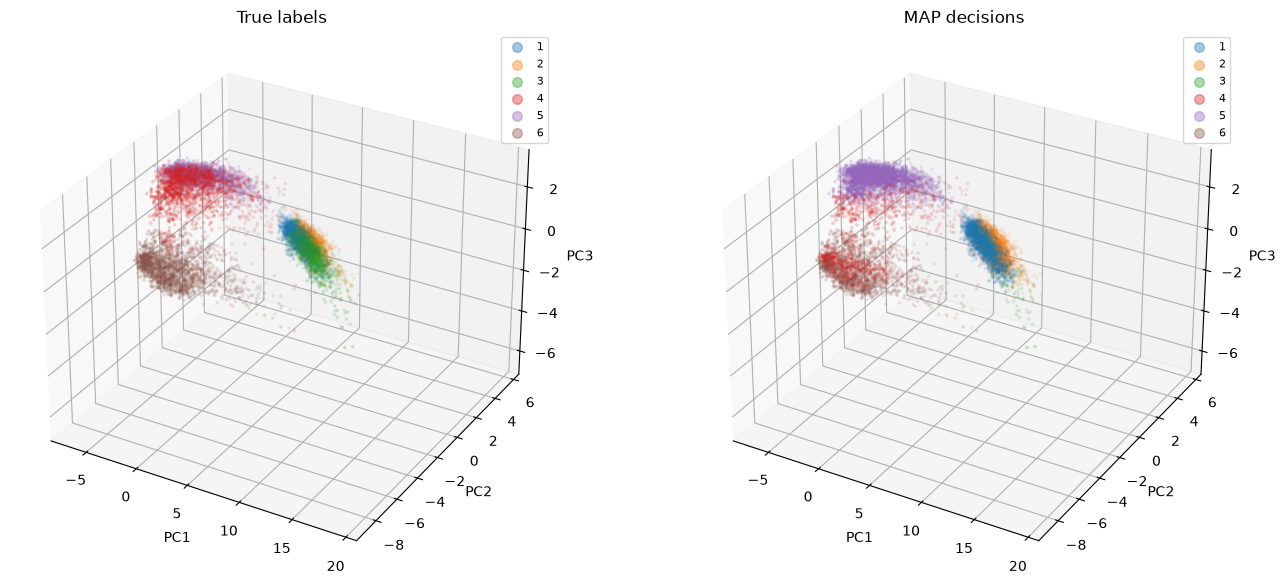

In [278]:
fig = plt.figure(figsize=(14, 6))
for p, (labels, name) in enumerate([(y, "True labels"), (D, "MAP decisions")], start=1):
    ax = fig.add_subplot(1, 2, p, projection="3d")
    for c in classes:
        pts = Z[labels == c]
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=3, alpha=0.4, label=str(c))
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title(name)
    ax.legend(markerscale=4, fontsize=8)
plt.tight_layout()
plt.show()